# Compressed Sensing: Sparse Signal Recovery of a Real Image

## Problem
Can a 128 by 128 photograph be recovered from a fraction of its pixels? If the image is sparse in a transform basis, compressed sensing says that m measurements, far fewer than the number of pixels, can suffice, using L1 minimisation.

## Data
- **Source:** `sklearn.datasets.load_sample_image('china.jpg')`, a colour photograph (427 by 640 pixels) bundled with scikit-learn. It is read from the local package, with no download.
- **Preparation:** converted to grayscale with the ITU-R 601 luma weights, centre-cropped to 128 by 128, scaled to $[0,1]$.

## Method
**Sparsity basis.** $x = \Psi s$, where $\Psi$ is the orthonormal 2-D inverse DCT and $s$ is the vector of DCT coefficients.

**Measurements.** Sample $m$ pixels uniformly at random, with index set $\Omega$. The measurement is $y = P_\Omega x = A s$, with $A = P_\Omega\Psi$.

**Recovery.** Solve the LASSO problem
$$\hat s = \arg\min_s \ \tfrac12\|As-y\|_2^2 + \lambda\|s\|_1$$
with FISTA, a Nesterov-accelerated ISTA:
$$s^{k+1} = \mathcal S_{\lambda}\big(z^k - A^\top(Az^k-y)\big), \qquad \mathcal S_\lambda(u)=\mathrm{sign}(u)\max(|u|-\lambda,0).$$
The step size is 1, which is valid because $\|A\|_2 = 1$. The image is $\hat x = \Psi \hat s$. The value of $\lambda$ is chosen on a 20% hold-out of the measured pixels, not on the ground-truth image, and the solver is then refit on all measured pixels.

**Baseline.** Linear interpolation of the sampled pixels onto the grid, with nearest-neighbour filling outside the convex hull.

**Metric.** $\mathrm{PSNR} = 10\log_{10}(1/\mathrm{MSE})$ for images with values in $[0,1]$.

full image (427, 640, 3) | gray crop (128, 128) | range 0.002 1.0


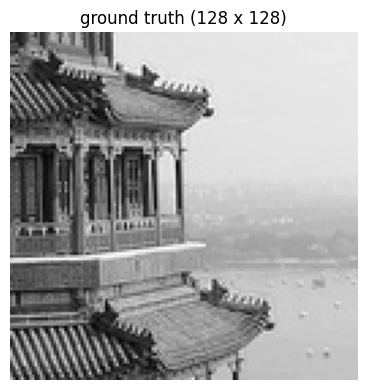

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import dctn, idctn
from scipy.interpolate import griddata
from sklearn.datasets import load_sample_image

SEED = 0
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)

img = load_sample_image("china.jpg").astype(float) / 255.0
gray = img @ np.array([0.299, 0.587, 0.114])
H, W_ = gray.shape
N = 128
r0, c0 = (H - N) // 2, (W_ - N) // 2
x_true = gray[r0:r0 + N, c0:c0 + N]
print("full image", img.shape, "| gray crop", x_true.shape, "| range", x_true.min().round(3), x_true.max().round(3))

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(x_true, cmap="gray", vmin=0, vmax=1); ax.set_title("ground truth (128 x 128)"); ax.axis("off")
plt.tight_layout(); plt.show()

### How sparse is the image in the DCT basis?
Keeping the $k$ largest DCT coefficients gives an oracle with full knowledge of the image. This sets an upper bound on what any sparse-recovery method can reach at a given sparsity.

In [2]:
coef = dctn(x_true, norm="ortho").ravel()
energy = np.sort(coef ** 2)[::-1]
cum = np.cumsum(energy) / energy.sum()
k99 = int(np.searchsorted(cum, 0.99) + 1)
print(f"Coefficients needed for 99% of energy: {k99} of {N*N} ({100*k99/(N*N):.1f}%)")

def psnr(a, b):
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def keep_top_k(k):
    idx = np.argsort(np.abs(coef))[::-1][:k]
    c = np.zeros_like(coef); c[idx] = coef[idx]
    return idctn(c.reshape(N, N), norm="ortho")

for frac in [0.01, 0.05, 0.10, 0.25, 0.40]:
    k = int(frac * N * N)
    print(f"oracle top {frac*100:>4.0f}% DCT coefficients ({k:>5}): PSNR = {psnr(x_true, np.clip(keep_top_k(k), 0, 1)):.2f} dB")

Coefficients needed for 99% of energy: 1796 of 16384 (11.0%)
oracle top    1% DCT coefficients (  163): PSNR = 18.74 dB
oracle top    5% DCT coefficients (  819): PSNR = 21.45 dB
oracle top   10% DCT coefficients ( 1638): PSNR = 23.28 dB
oracle top   25% DCT coefficients ( 4096): PSNR = 27.29 dB
oracle top   40% DCT coefficients ( 6553): PSNR = 31.02 dB


### Operators and FISTA solver

In [3]:
def A_op(s, omega):
    return idctn(s.reshape(N, N), norm="ortho").ravel()[omega]

def At_op(r, omega):
    full = np.zeros(N * N)
    full[omega] = r
    return dctn(full.reshape(N, N), norm="ortho").ravel()

def fista(y, omega, lam, n_iter=500):
    s = np.zeros(N * N)
    z = s.copy()
    t = 1.0
    for _ in range(n_iter):
        grad = At_op(A_op(z, omega) - y, omega)
        u = z - grad
        s_new = np.sign(u) * np.maximum(np.abs(u) - lam, 0.0)
        t_new = 0.5 * (1 + np.sqrt(1 + 4 * t * t))
        z = s_new + ((t - 1) / t_new) * (s_new - s)
        s, t = s_new, t_new
    return s

def reconstruct(s):
    return np.clip(idctn(s.reshape(N, N), norm="ortho"), 0, 1)

# check: ||A||_2 should be 1 (orthonormal Psi, coordinate projection), so step size 1 is valid.
# Power iteration on A^T A estimates ||A||_2^2.
omega_test = np.sort(rng.choice(N * N, 1638, replace=False))
v = rng.normal(size=N * N)
for _ in range(100):
    v = At_op(A_op(v, omega_test), omega_test)
    sq_norm = np.linalg.norm(v)
    v = v / sq_norm
print("power-iteration estimate of ||A||_2^2:", round(sq_norm, 6))

# check: is 500 FISTA iterations enough? Compare objective at 500 and 3000 iterations.
def lasso_obj(s, y, omega, lam):
    return 0.5 * np.sum((A_op(s, omega) - y) ** 2) + lam * np.sum(np.abs(s))
y_t = x_true.ravel()[omega_test]
for lam_t in [0.01, 0.1]:
    o500 = lasso_obj(fista(y_t, omega_test, lam_t, 500), y_t, omega_test, lam_t)
    o3000 = lasso_obj(fista(y_t, omega_test, lam_t, 3000), y_t, omega_test, lam_t)
    print(f"lambda={lam_t}: objective after 500 iters {o500:.4f}, after 3000 iters {o3000:.4f}")

power-iteration estimate of ||A||_2^2: 1.0


lambda=0.01: objective after 500 iters 4.5848, after 3000 iters 4.5848


lambda=0.1: objective after 500 iters 29.4442, after 3000 iters 29.4442


In [4]:
LAMBDAS = np.logspace(-3, -0.5, 6)

def choose_lambda(y, omega, rng):
    perm = rng.permutation(len(omega))
    n_val = len(omega) // 5
    val, fit = perm[:n_val], perm[n_val:]
    scores = {}
    for lam in LAMBDAS:
        s = fista(y[fit], omega[fit], lam)
        pred = idctn(s.reshape(N, N), norm="ortho").ravel()[omega[val]]
        scores[lam] = np.mean((pred - y[val]) ** 2)
    best = min(scores, key=scores.get)
    return best, scores

def interp_recon(y, omega):
    pts = np.column_stack(np.unravel_index(omega, (N, N)))
    grid = tuple(np.mgrid[0:N, 0:N])
    lin = griddata(pts, y, grid, method="linear")
    near = griddata(pts, y, grid, method="nearest")
    return np.clip(np.where(np.isnan(lin), near, lin), 0, 1)

sample_rates = [0.10, 0.25, 0.40]
results = []
recons = {}
for rate in sample_rates:
    m = int(round(rate * N * N))
    omega = np.sort(rng.choice(N * N, m, replace=False))
    y = x_true.ravel()[omega]
    t0 = time.time()
    lam, scores = choose_lambda(y, omega, rng)
    s_hat = fista(y, omega, lam)
    rec_cs = reconstruct(s_hat)
    t_cs = time.time() - t0
    rec_int = interp_recon(y, omega)
    p_cs, p_int = psnr(x_true, rec_cs), psnr(x_true, rec_int)
    results.append(dict(rate=rate, measurements=m, lambda_chosen=lam,
                        nonzero_coefs=int(np.sum(np.abs(s_hat) > 1e-8)),
                        psnr_cs=p_cs, psnr_interp=p_int, cs_time_s=t_cs))
    recons[rate] = (rec_cs, rec_int)

res = pd.DataFrame(results).round(3)
print(res.to_string(index=False))

 rate  measurements  lambda_chosen  nonzero_coefs  psnr_cs  psnr_interp  cs_time_s
 0.10          1638            0.1            234   16.888       17.883      6.510
 0.25          4096            0.1            933   18.362       19.738      6.795
 0.40          6554            0.1           1755   19.603       21.211      6.875


### Reconstructions
Top row: L1 / FISTA recovery. Bottom row: linear interpolation of the same measured pixels.

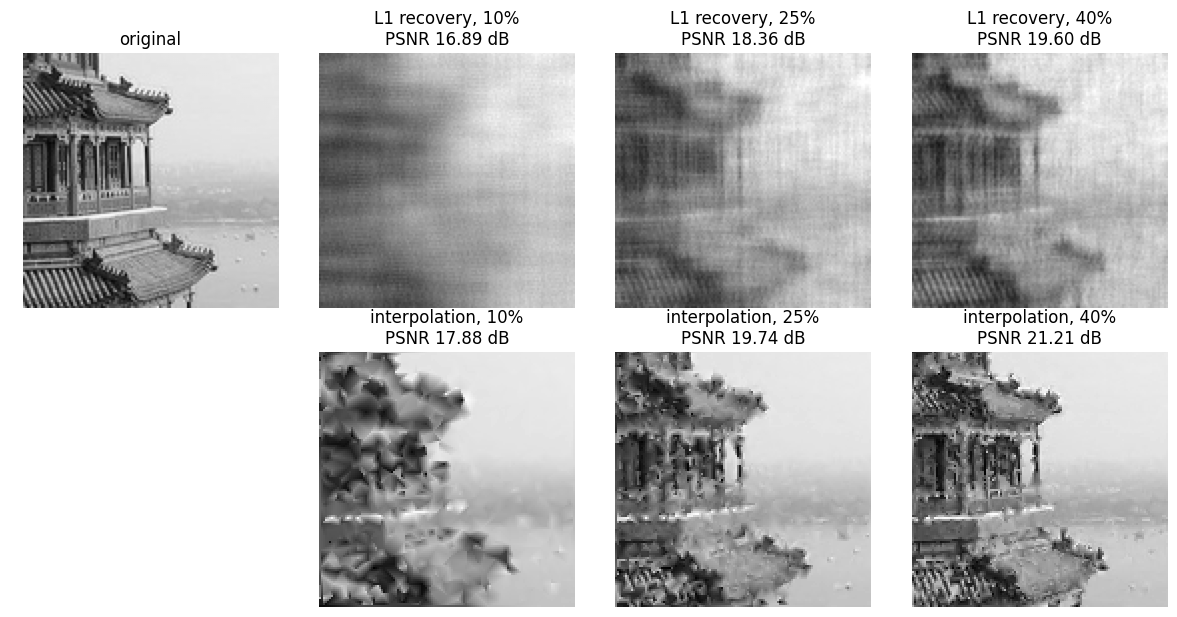

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
axes[0, 0].imshow(x_true, cmap="gray", vmin=0, vmax=1); axes[0, 0].set_title("original")
axes[1, 0].axis("off")
for j, rate in enumerate(sample_rates, start=1):
    rc, ri = recons[rate]
    p_cs = res.loc[res.rate == rate, "psnr_cs"].item()
    p_i = res.loc[res.rate == rate, "psnr_interp"].item()
    axes[0, j].imshow(rc, cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"L1 recovery, {int(rate*100)}%\nPSNR {p_cs:.2f} dB")
    axes[1, j].imshow(ri, cmap="gray", vmin=0, vmax=1)
    axes[1, j].set_title(f"interpolation, {int(rate*100)}%\nPSNR {p_i:.2f} dB")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

### PSNR versus sampling rate

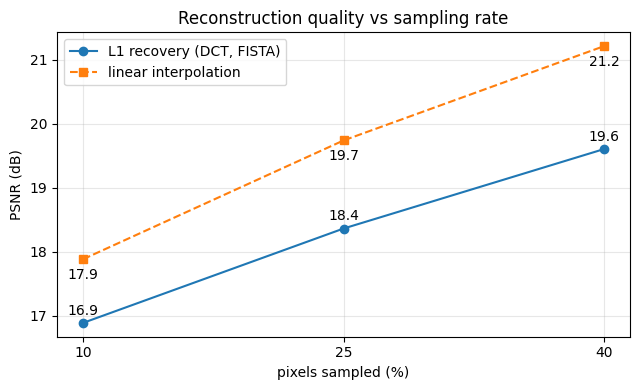

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(res.rate * 100, res.psnr_cs, "o-", label="L1 recovery (DCT, FISTA)")
ax.plot(res.rate * 100, res.psnr_interp, "s--", label="linear interpolation")
for _, rr in res.iterrows():
    ax.annotate(f"{rr.psnr_cs:.1f}", (rr.rate * 100, rr.psnr_cs), textcoords="offset points", xytext=(0, 6), ha="center")
    ax.annotate(f"{rr.psnr_interp:.1f}", (rr.rate * 100, rr.psnr_interp), textcoords="offset points", xytext=(0, -14), ha="center")
ax.set_xlabel("pixels sampled (%)"); ax.set_ylabel("PSNR (dB)")
ax.set_xticks([10, 25, 40]); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Reconstruction quality vs sampling rate")
plt.tight_layout(); plt.show()

## Results

- Image: 128 by 128 grayscale centre crop of `china.jpg`. The DCT coefficients needed for 99% of the energy number 1,796 of 16,384 (11.0%).
- Oracle (keeps the largest DCT coefficients with full knowledge of the image): PSNR 18.74 dB at 1%, 21.45 dB at 5%, 23.28 dB at 10%, 27.29 dB at 25%, 31.02 dB at 40%.
- L1 recovery (FISTA, lambda chosen on a hold-out; 0.1 at every rate): PSNR 16.89 dB at 10% (1,638 pixels), 18.36 dB at 25% (4,096 pixels), 19.60 dB at 40% (6,554 pixels).
- Linear interpolation of the same pixels: PSNR 17.88 dB at 10%, 19.74 dB at 25%, 21.21 dB at 40%.
- **Failure:** interpolation beats L1 recovery at all three sampling rates. The L1 result also sits well below the oracle curve at the same number of coefficients.
- Solver checks: the power-iteration estimate of ||A||_2^2 is 1.0, so step size 1 is valid. The objective is identical after 500 and 3000 iterations, so the gap is not an unconverged solver.
- Cost: about 6.5 to 6.9 seconds per sampling rate, including the lambda search.
- Caveats: each rate is a single random draw (seed 0), with no repeats. The image is a single crop. The failure is reported as measured; the likely cause (the sampling is not incoherent enough with the DCT basis) was not tested here.

## Conclusions
1. **In this experiment, L1 recovery lost to simple interpolation at every sampling rate.** Sampling 10%, 25% and 40% of the pixels of a 128 x 128 crop of a real photograph, L1 (LASSO in the DCT basis) reaches 16.9, 18.4 and 19.6 dB PSNR, against 17.9, 19.7 and 21.2 dB for plain linear interpolation. The solver was checked (the objective did not change between 500 and 3,000 iterations), so this is not an optimisation failure.
2. **The likely reason is that the image is not sparse enough.** 99% of the image energy needs 1,796 of 16,384 DCT coefficients (11%), so the signal is only approximately sparse. Even an oracle that keeps the best 10% of the coefficients reaches 23.3 dB, so recovery from 10% of the measurements cannot get close to that. Natural images have a lot of structure that interpolation already exploits. This explanation was not tested separately (for example with a total-variation prior or a sparser image).
3. **Compressed sensing needs sparsity and incoherence to pay off.** Its guarantees say that a sufficiently sparse signal can be recovered from far fewer random measurements than pixels; they do not say it beats a good simple baseline on an approximately sparse natural image with plain pixel sampling. Real systems (such as MRI) use sampling patterns and priors designed for the task.
4. **Limits.** One image, one sparsifying basis (DCT) and a single reconstruction algorithm (FISTA-LASSO); regularisation was chosen from a short grid (0.01 and 0.1).

**Takeaway for the interview:** report negative results with the diagnostic. Always compare with a simple baseline, and remember that the theory is about exactly sparse signals and incoherent sampling.